<div style="background-color:#7BAFD4;border-radius:18px;padding:22px 26px;margin-bottom:18px;">
  <div style="font-family:Impact,'Arial Black',Arial,sans-serif;font-size:42px;font-weight:900;letter-spacing:2px;line-height:1;color:white;">GEOG 592</div>
  <div style="font-family:Arial,Helvetica,sans-serif;font-size:22px;font-weight:700;color:#13294B;margin-top:8px;">GIS Programming &middot; Week 10</div>
  <div style="font-family:Arial,Helvetica,sans-serif;font-size:16px;color:#13294B;margin-top:6px;">Automated Atlas: Dams in North Carolina Counties</div>
</div>

**Hailey Rodriguez**

This notebook builds a one-page-per-county atlas of North Carolina. Each page uses a **spatial join** between NC county polygons (U.S. Census Bureau, 2024 cartographic boundaries) and dam locations from the **National Inventory of Dams (NID)**, maintained by the U.S. Army Corps of Engineers. String concatenation turns each join result into a sentence like *"There are 112 dams in Wake County."*

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from pathlib import Path

## 1. County polygons

In [2]:
local_county_zip = Path("../week09/cb_2024_us_county_500k.zip")
census_url = "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_county_500k.zip"

counties = gpd.read_file(local_county_zip if local_county_zip.exists() else census_url)

# NC only, projected to NC State Plane (ft), alphabetical like the class atlas
nc_counties = (
    counties.loc[counties["STATEFP"] == "37"]
    .to_crs(6543)
    .sort_values("NAME")
    .reset_index(drop=True)
)
print(len(nc_counties), "counties")

100 counties


## 2. Additional vector dataset: dams
The NID publishes the full national inventory as a CSV.

In [3]:
dam_csv = Path("nc_dams.csv")
nid_national_url = "https://nid.sec.usace.army.mil/api/nation/csv"

def read_nid_csv(source):
    # Find which of the first few lines holds the real header
    peek = pd.read_csv(source, header=None, nrows=5, low_memory=False)
    header_row = next(i for i, row in peek.iterrows()
                      if row.astype(str).str.strip().eq("Latitude").any())
    return pd.read_csv(source, header=header_row, low_memory=False)

dams_df = read_nid_csv(dam_csv if dam_csv.exists() else nid_national_url)

# If we pulled the national file, keep North Carolina only
print("Rows read:", len(dams_df))
if "State" in dams_df.columns:
    print("State values look like:", dams_df["State"].dropna().unique()[:5])
    state = dams_df["State"].astype(str).str.strip().str.lower()
    dams_df = dams_df[state.isin(["north carolina", "nc"])]

# Make sure coordinates are numbers, not text
dams_df["Latitude"] = pd.to_numeric(dams_df["Latitude"], errors="coerce")
dams_df["Longitude"] = pd.to_numeric(dams_df["Longitude"], errors="coerce")
dams_df = dams_df.dropna(subset=["Latitude", "Longitude"])

# NC longitudes are negative (west of Greenwich); fix any missing minus signs
dams_df.loc[dams_df["Longitude"] > 0, "Longitude"] *= -1
print(len(dams_df), "NC dams with coordinates")
dams_df.head()

Rows read: 3680
State values look like: <StringArray>
['NC']
Length: 1, dtype: str
3680 NC dams with coordinates


,Dam Name,Other Names,Former Names,State or Federal Agency ID,NID ID,Federal ID,Longitude,Latitude,County,River or Stream Name,...,Operational Status Date,Operational Status,Built Under the Authority of the Secretary of Agriculture,NRCS Watershed Dam Authorization,Primary Owner Type,Primary Purpose,Primary Dam Type,Inundation Maps Added to NID?,Data Last Updated,"Non-USACE Dam with USACE Flood Control Storage Authority (Section 7, Flood Control Act of 1944)"
0,Phillips Dam,NaN,NaN,HENDE-104,NC03075,NC03075,-82.3761,35.2315,Henderson,NaN,...,NaN,NaN,No,NaN,X,R,RE,No,06/16/2026,No
1,Matthews Lake Dam,NaN,NaN,SAMPS-025,NC01188,NC01188,-78.5078,35.0605,Sampson,NaN,...,NaN,NaN,No,NaN,X,R,RE,No,06/16/2026,No
2,Nixon Dam,NaN,NaN,UNION-068,NC04411,NC04411,-80.7516,34.9419,Union,NaN,...,NaN,NaN,No,NaN,X,R,RE,No,06/16/2026,No
3,Gentz Dam,NaN,NaN,DURHA-153,NC07014,NC07014,-78.8138,36.0076,Durham,NaN,...,NaN,NaN,No,NaN,P,O,RE,No,06/16/2026,No
4,Cofrin Dam,NaN,NaN,TRANS-104,NC07753,NC07753,-82.9544,35.1478,Transylvania,NaN,...,NaN,NaN,No,NaN,P,O,RE,No,06/16/2026,No


CSV → points. Coordinates are lat/long (WGS84, EPSG:4326), then reprojected to match the counties.

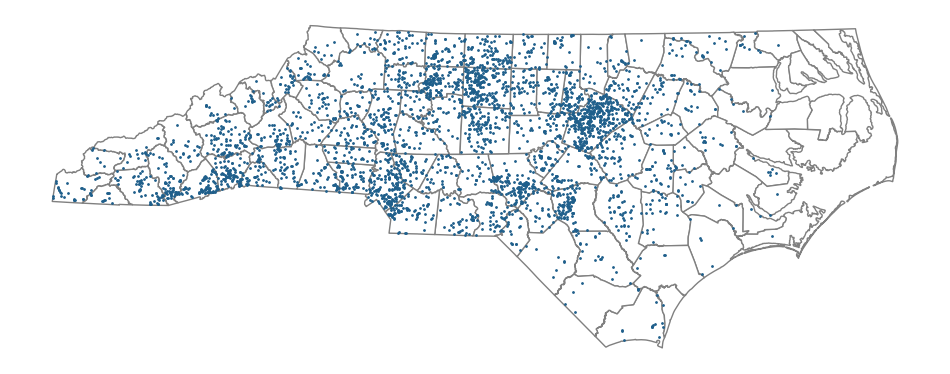

In [4]:
dams = gpd.GeoDataFrame(
    dams_df,
    geometry=gpd.points_from_xy(dams_df["Longitude"], dams_df["Latitude"]),
    crs=4326,
).to_crs(nc_counties.crs)

ax = nc_counties.plot(edgecolor="gray", facecolor="white", figsize=(12, 5))
dams.plot(ax=ax, markersize=1, color="#1f5f8b")
ax.set_axis_off()

## 3. Spatial join
`gpd.sjoin(..., predicate="within")` tags every dam with the county it sits in. Grouping by county name then gives the number of dams per county. Counties with no dams get a 0 instead of being dropped.

In [5]:
dams_joined = gpd.sjoin(
    dams,
    nc_counties[["NAME", "geometry"]],
    how="inner",
    predicate="within",
)

dam_counts = dams_joined.groupby("NAME").size()
nc_counties["dam_count"] = nc_counties["NAME"].map(dam_counts).fillna(0).astype(int)

nc_counties.sort_values("dam_count", ascending=False)[["NAME", "dam_count"]].head(10)

,NAME,dam_count
91,Wake,364
40,Guilford,186
59,Mecklenburg,157
62,Moore,136
33,Forsyth,113
75,Randolph,110
78,Rockingham,93
25,Cumberland,91
44,Henderson,85
48,Iredell,84


Hazard potential is one of the most useful NID fields: it says how bad things would be downstream **if** the dam failed (it is not a rating of the dam's condition). I'll count **High** hazard dams per county for a second sentence.

In [6]:
hazard_col = "Hazard Potential Classification"
has_hazard = hazard_col in dams_joined.columns

if has_hazard:
    dams_joined["hazard"] = dams_joined[hazard_col].fillna("Undetermined").astype(str).str.strip()
    high_counts = dams_joined[dams_joined["hazard"] == "High"].groupby("NAME").size()
    nc_counties["high_hazard"] = nc_counties["NAME"].map(high_counts).fillna(0).astype(int)
else:
    nc_counties["high_hazard"] = 0
    print("No hazard column found, skipping the hazard breakdown")

## 4. Building blocks for each page
These are the class functions, adapted: the county map now shows its dams, and the info panel writes the spatial join result as a sentence.

In [7]:
COUNTY_FILL = "#dfe9e4"
DAM_COLOR = "#1f5f8b"
HAZARD_COLORS = {"High": "#b5413a", "Significant": "#e39b3b",
                 "Low": "#7b9b90", "Undetermined": "#bbbbbb"}

def county_map(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]
    selected.plot(ax=ax, edgecolor="black", facecolor=COUNTY_FILL)
    county_dams = dams_joined[dams_joined["NAME"] == county]
    if len(county_dams) > 0:
        county_dams.plot(ax=ax, color=DAM_COLOR, markersize=18,
                         marker="^", edgecolor="white", linewidth=0.4)
    ax.set_axis_off()


def locator_map(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]
    nc_counties.plot(ax=ax, edgecolor="gray", facecolor="white", linewidth=0.3)
    selected.plot(ax=ax, edgecolor="black", facecolor=DAM_COLOR)
    ax.set_axis_off()

In [8]:
def dam_sentence(county):
    row = nc_counties.loc[nc_counties["NAME"] == county].iloc[0]
    n = row["dam_count"]

    # String concatenation, with grammar that changes for 0 / 1 / many
    if n == 0:
        phrase = "There are no inventoried dams in " + county + " County."
    elif n == 1:
        phrase = "There is 1 dam in " + county + " County."
    else:
        phrase = "There are " + str(n) + " dams in " + county + " County."

    if has_hazard and n > 0:
        h = row["high_hazard"]
        phrase += "\n\n" + str(h) + " of " + ("it is" if n == 1 else "them are") + \
                  " classified as High hazard potential."
    return phrase


def county_info(county, ax):
    row = nc_counties.loc[nc_counties["NAME"] == county].iloc[0]
    ax.text(0.0, 0.95, str(row["dam_count"]), transform=ax.transAxes,
            fontsize=54, fontweight="bold", color=DAM_COLOR, va="top")
    ax.text(0.0, 0.50, dam_sentence(county), transform=ax.transAxes,
            fontsize=13, va="top", wrap=True)
    ax.set_axis_off()


def hazard_bar(county, ax):
    county_dams = dams_joined[dams_joined["NAME"] == county]
    if not has_hazard or len(county_dams) == 0:
        ax.set_axis_off()
        return
    order = [k for k in HAZARD_COLORS if k in county_dams["hazard"].unique()]
    counts = county_dams["hazard"].value_counts().reindex(order)
    ax.barh(counts.index, counts.values, color=[HAZARD_COLORS[k] for k in order])
    ax.invert_yaxis()
    for i, v in enumerate(counts.values):
        ax.text(v, i, " " + str(v), va="center", fontsize=10)
    ax.set_title("Dams by hazard potential", fontsize=11, loc="left")
    for side in ["top", "right", "bottom"]:
        ax.spines[side].set_visible(False)
    ax.set_xticks([])

Test it on one county before looping.

In [9]:
print(dam_sentence("Orange"))
print()
print(dam_sentence("Wake"))

There are 43 dams in Orange County.

0 of them are classified as High hazard potential.

There are 364 dams in Wake County.

0 of them are classified as High hazard potential.


## 5. Page layout
Same `fig.add_axes` layout from class, with the hazard bar chart in place of the land/water pie.

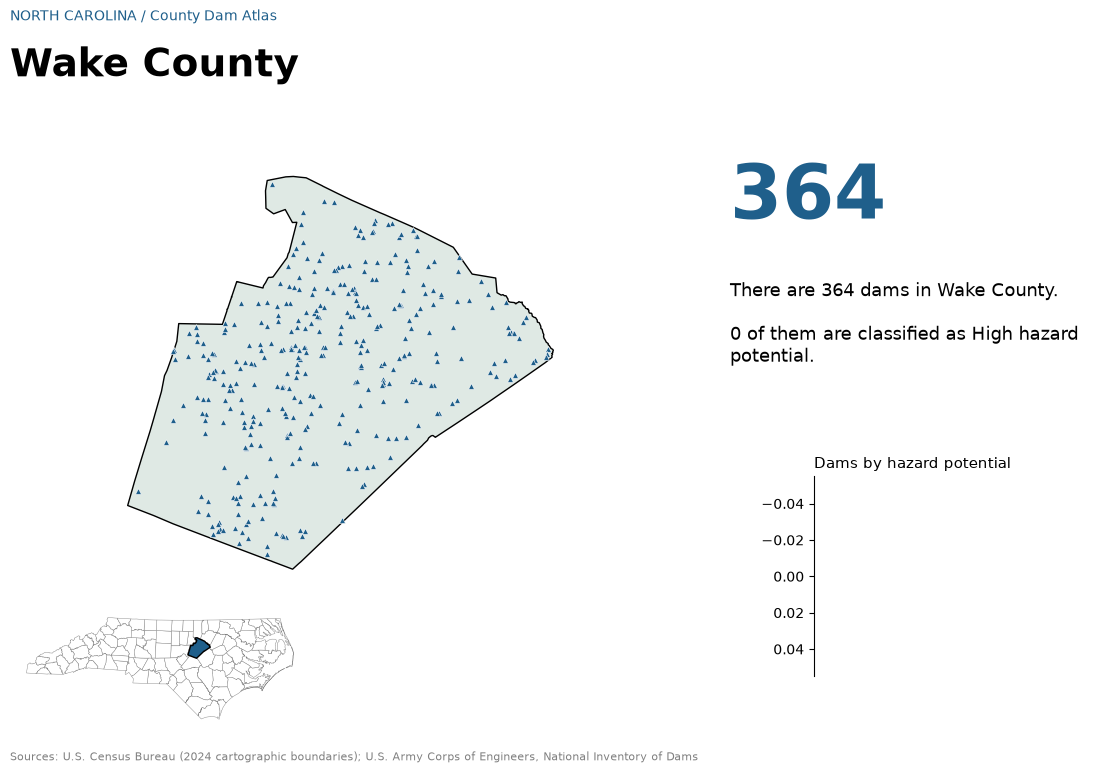

In [10]:
def county_figure(county, pdf=None):
    fig = plt.figure(figsize=(12, 8))

    # [left, bottom, width, height] as fractions of the figure
    ax_county = fig.add_axes([0.05, 0.23, 0.55, 0.54])
    ax_locator = fig.add_axes([0.05, 0.06, 0.25, 0.14])
    ax_info = fig.add_axes([0.65, 0.45, 0.30, 0.33])
    ax_bar = fig.add_axes([0.72, 0.12, 0.23, 0.25])

    county_map(county, ax_county)
    locator_map(county, ax_locator)
    county_info(county, ax_info)
    hazard_bar(county, ax_bar)

    fig.text(0.05, 0.94, "NORTH CAROLINA / County Dam Atlas", fontsize=10, color=DAM_COLOR)
    fig.text(0.05, 0.87, county + " County", fontsize=28, fontweight="bold")
    fig.text(0.05, 0.015,
             "Sources: U.S. Census Bureau (2024 cartographic boundaries); "
             "U.S. Army Corps of Engineers, National Inventory of Dams",
             fontsize=8, color="gray")

    if pdf is None:
        plt.show()
    else:
        pdf.savefig(fig, dpi=50)
        plt.close(fig)

county_figure("Wake")

## 6. Build the full atlas
One page per county, alphabetical. This takes a minute.

In [12]:
with PdfPages("NC_Dam_Atlas.pdf") as pdf:
    for county in nc_counties["NAME"]:
        county_figure(county, pdf)

print("Atlas size:", round(Path("NC_Dam_Atlas.pdf").stat().st_size / 1e6, 1), "MB")

Atlas size: 33.6 MB


## 7. Two sample pages for GitHub
The assignment asks for two pages, not the whole atlas (unless it's under 50 MB). This saves Orange and Wake as a separate 2-page PDF.

In [ ]:
with PdfPages("NC_Dam_Atlas_sample_pages.pdf") as pdf:
    for county in ["Orange", "Wake"]:
        county_figure(county, pdf)

### Notes
- The NID only includes dams that meet federal criteria (mostly by height, storage, or hazard), so a county showing 0 may still have small dams that aren't in the inventory.
- Hazard potential describes the consequences downstream if a dam failed. It is **not** a measure of the dam's condition or how likely it is to fail.